# Ensino superior no Brasil, 2009–2024: Censo da Educação Superior + ENADE + IBGE

**Etapa 1 do projeto**: coleta → análise exploratória → limpeza/tratamento → visualizações.

| | |
|---|---|
| **Fonte principal** | INEP – Microdados do Censo da Educação Superior (cursos de graduação), 2009–2024 |
| **Fontes integradas** | INEP – Microdados do ENADE (2017, 2018, 2019, 2021, 2023); IBGE – população por UF (SIDRA), municípios e malha de UFs |
| **Licença** | Dados abertos do Governo Federal (INEP e IBGE), uso livre com citação da fonte |
| **Recorte** | Brasil, todas as UFs; graduação (bacharelado, licenciatura, tecnológico), presencial e EAD |

### Perguntas de pesquisa
1. **P1.** Como evoluíram ingressantes e matrículas de graduação entre 2009 e 2024, e quanto desse crescimento veio do EAD?
2. **P2.** Como o acesso ao ensino superior (matrículas por 100 mil habitantes) varia entre UFs e regiões, e a desigualdade regional diminuiu?
3. **P3.** Qual o peso da rede privada e dos programas federais (FIES, PROUNI) no acesso, e como isso mudou?
4. **P4.** O perfil do ingressante mudou (sexo, cor/raça, idade 25+, escola pública)?
5. **P5.** O desempenho no ENADE difere entre rede (pública × privada), modalidade (presencial × EAD) e área?

### Como reproduzir
```bash
python src/coleta.py --benchmark   # bronze: download + Parquet + metadados + benchmark CSV×Parquet
python src/limpeza.py              # silver: base tratada + reports/log_limpeza.csv
python src/gold.py                 # gold: tabelas agregadas para as perguntas
jupyter nbconvert --to notebook --execute --inplace notebooks/censo_educacao_superior.ipynb
```

In [1]:
import sys, warnings
from pathlib import Path

import duckdb
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import seaborn as sns

RAIZ = Path.cwd().resolve()
if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent
sys.path.insert(0, str(RAIZ / "src"))
import config as C
import limpeza as L   # reaproveita listas de colunas e a função nulo()

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40, "display.width", 160, "display.float_format", "{:,.2f}".format)
C.FIGURAS.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
for s in ["SET memory_limit = '4GB'", "SET threads = 4", "SET enable_progress_bar = false",
          f"SET temp_directory = '{C.DATA / '_duckdb_tmp'}'"]:
    con.execute(s)
sql = lambda q: con.execute(q).df()

con.execute(f"create or replace view bronze_cursos as select * from read_parquet('{C.BRONZE}/censo_cursos/*/*.parquet', hive_partitioning=true, union_by_name=true)")
con.execute(f"create or replace view bronze_enade as select * from read_parquet('{C.BRONZE}/enade_desempenho/*/*.parquet', hive_partitioning=true, union_by_name=true)")
con.execute(f"create or replace view silver_cursos as select * from read_parquet('{C.SILVER}/censo_cursos/*/*.parquet', hive_partitioning=true)")
con.execute(f"create or replace view silver_enade as select * from read_parquet('{C.SILVER}/enade_desempenho/*/*.parquet', hive_partitioning=true)")
gold = {p.stem: pd.read_parquet(p) for p in sorted(C.GOLD.glob("*.parquet"))}

# estilo único para todas as figuras
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 12,
                     "axes.spines.top": False, "axes.spines.right": False})
COR = {"Presencial": "#3b6fb6", "EAD": "#e07b39", "Pública": "#2a9d8f", "Privada": "#8e5ea2"}
mil = mtick.FuncFormatter(lambda x, _: f"{x/1e6:.1f} mi" if abs(x) >= 1e6 else f"{x/1e3:.0f} mil")
pct = mtick.PercentFormatter(1.0, decimals=0)

def salvar(fig, nome):
    fig.savefig(C.FIGURAS / f"{nome}.png", bbox_inches="tight", dpi=150)

print("tabelas gold:", list(gold))

tabelas gold: ['antes_depois_categoria', 'area_ano', 'enade_curso', 'enade_resumo', 'perfil_ingressantes', 'serie_brasil', 'uf_ano']


## 1. Coleta

A coleta (`src/coleta.py`) baixa os ZIPs do INEP com repetição em caso de erro (5 tentativas, espera exponencial) e
pula arquivos já baixados (verificação por tamanho/MD5). Extrai os CSVs (`;`, latin-1), converte para Parquet
particionado por ano (`data/bronze/<tabela>/ano=AAAA/`) e registra os metadados de cada arquivo.

In [2]:
meta = pd.read_csv(C.REPORTS / "metadados_coleta.csv")
resumo = (meta.groupby(["fonte", "tabela"], as_index=False)
              .agg(arquivos=("arquivo", "count"), anos=("ano", lambda s: f"{int(s.min())}–{int(s.max())}" if s.notna().any() else "–"),
                   linhas=("linhas", "sum"), colunas_min=("colunas", "min"), colunas_max=("colunas", "max"),
                   mb_zip=("bytes", lambda s: s.drop_duplicates().sum() / 1e6),
                   mb_csv=("bytes_csv", lambda s: s.sum() / 1e6), mb_parquet=("bytes_parquet", lambda s: s.sum() / 1e6)))
resumo["reducao_%"] = 100 * (1 - resumo.mb_parquet / resumo.mb_csv)
display(resumo)
tot = resumo[resumo.mb_csv > 0]
print(f"Linhas coletadas (todas as tabelas): {int(resumo.linhas.sum()):,}")
print(f"Linhas usadas nas análises (Censo cursos + ENADE desempenho): "
      f"{int(resumo.loc[resumo.tabela.isin(['censo_cursos', 'enade_desempenho']), 'linhas'].sum()):,}")
print(f"CSV {tot.mb_csv.sum()/1e3:.2f} GB → Parquet {tot.mb_parquet.sum()/1e3:.2f} GB "
      f"(redução de {100*(1 - tot.mb_parquet.sum()/tot.mb_csv.sum()):.1f}%)")
print(f"ZIPs baixados: {meta.drop_duplicates('arquivo').bytes.sum()/1e9:.2f} GB")

,fonte,tabela,arquivos,anos,linhas,colunas_min,colunas_max,mb_zip,mb_csv,mb_parquet,reducao_%
0,IBGE – Localidades,ibge_municipios,1,–,5571,5,5,2.76,0.00,0.00,NaN
1,IBGE – SIDRA,sidra_1378_censo2010,1,–,27,4,4,0.01,0.00,0.00,NaN
2,IBGE – SIDRA,sidra_4709_censo2022,1,–,27,4,4,0.01,0.00,0.00,NaN
3,IBGE – SIDRA,sidra_6579_estimativas,1,–,594,4,4,0.13,0.00,0.00,NaN
4,INEP – Censo da Educação Superior,censo_cursos,16,2009–2024,3851933,200,223,676.14,"2,309.13",157.70,93.17
5,INEP – Censo da Educação Superior,censo_ies,16,2009–2024,39363,81,84,676.14,15.23,5.00,67.15
6,INEP – ENADE,enade_curso,5,2017–2023,2415570,10,10,348.70,106.15,1.03,99.03
7,INEP – ENADE,enade_desempenho,5,2017–2023,2415570,44,52,348.70,618.42,78.84,87.25
8,INEP – ENADE,enade_idade,5,2017–2023,2415570,3,3,348.70,38.01,4.76,87.47
9,INEP – ENADE,enade_sexo,5,2017–2023,2415570,3,3,348.70,39.62,4.30,89.15


Linhas coletadas (todas as tabelas): 13,559,795
Linhas usadas nas análises (Censo cursos + ENADE desempenho): 6,267,503
CSV 3.13 GB → Parquet 0.25 GB (redução de 92.0%)
ZIPs baixados: 1.03 GB


In [3]:
bench_path = C.REPORTS / "benchmark_csv_parquet.csv"
if bench_path.exists():
    bench = pd.read_csv(bench_path)
    b = bench.groupby("tabela")[["mb_csv", "mb_parquet", "seg_leitura_csv", "seg_leitura_parquet"]].sum()
    b["reducao_tamanho_%"] = 100 * (1 - b.mb_parquet / b.mb_csv)
    b["leitura_x_mais_rapida"] = b.seg_leitura_csv / b.seg_leitura_parquet
    display(b.round(2))
else:
    print("Rode `python src/coleta.py --so-benchmark` para gerar o benchmark.")

,mb_csv,mb_parquet,seg_leitura_csv,seg_leitura_parquet,reducao_tamanho_%,leitura_x_mais_rapida
tabela,,,,,,
censo_cursos,"2,309.13",157.70,2.78,3.47,93.17,0.80
censo_ies,15.23,5.00,0.19,0.12,67.15,1.57
enade_curso,106.15,1.03,0.20,0.10,99.03,2.09
enade_desempenho,618.42,78.84,0.56,0.47,87.25,1.18
enade_idade,38.01,4.76,0.14,0.09,87.47,1.60
enade_sexo,39.62,4.30,0.06,0.04,89.15,1.33


In [4]:
# leitura seletiva: só 3 colunas do Censo 2024. O Parquet é colunar e lê apenas o necessário.
import time
csv24 = C.BRONZE / "_tmp_csv" / "censo_cursos" / "2024.csv"
pq24 = C.BRONZE / "censo_cursos" / "ano=2024" / "parte.parquet"
usar = ["CO_CURSO", "TP_MODALIDADE_ENSINO", "QT_MAT"]
if csv24.exists():
    t0 = time.perf_counter(); pd.read_csv(csv24, sep=";", usecols=usar, dtype=str); t_csv = time.perf_counter() - t0
    t0 = time.perf_counter(); pd.read_parquet(pq24, columns=usar); t_pq = time.perf_counter() - t0
    print(f"3 colunas do Censo 2024: CSV {t_csv:.2f}s × Parquet {t_pq:.3f}s ({t_csv/t_pq:.0f}× mais rápido)")

3 colunas do Censo 2024: CSV 0.75s × Parquet 0.016s (47× mais rápido)


O ganho do Parquet está sobretudo no **disco** (−92% no total) e na **leitura seletiva de colunas**. Com o leitor CSV
multithread do pyarrow, ler o arquivo **inteiro** em pandas fica com tempo parecido nos dois formatos, porque o custo dominante
passa a ser montar centenas de colunas de texto na memória. A primeira versão do benchmark, com o leitor CSV padrão do pandas,
foi morta por falta de memória no Censo 2022 (cerca de 400 MB de CSV), o que mostra também o custo de memória do CSV.

**Dificuldades impostas pela fonte**

- **Certificado TLS incompleto no `download.inep.gov.br`**: o servidor não envia o certificado intermediário (RNP ICPEdu/GlobalSign).
  Em vez de desligar a verificação, o script baixa o intermediário oficial pela URL AIA e monta um *bundle* (`certs/`).
- **Mudança de layout entre anos**: o número de colunas do arquivo de cursos varia ao longo da série (ver `colunas_min`/`colunas_max`);
  a leitura usa `union_by_name` e colunas ausentes num ano viram nulo. Categorias administrativas 6/8/9 só existem em 2009.
- **ENADE com LGPD**: desde 2017 os microdados vêm em vários arquivos (`arq1`…`arq6`) com linhas embaralhadas entre si;
  a única chave comum é `CO_CURSO`. Sexo e idade só podem ser analisados **agregados por curso**. 2020 e 2022 não têm ENADE publicado.
- **Formatos**: ZIP com CSV `;` em latin-1, códigos CINE com aspas triplicadas, marcador `.` para “não se aplica”; IBGE via API JSON (SIDRA/Localidades/Malhas).

## 2. Análise exploratória (sobre o **bronze**, antes da limpeza)

### 2.1 Visão geral: dimensões, tipos e memória

In [5]:
dims = meta[meta.tabela.isin(["censo_cursos", "enade_desempenho"])].pivot_table(
    index="ano", columns="tabela", values=["linhas", "colunas"], aggfunc="sum")
dims.index = dims.index.astype(int)
display(dims.astype("Int64"))

colunas                        linhas                 
tabela censo_cursos enade_desempenho censo_cursos enade_desempenho
ano                                                               
2009            200             <NA>        52146             <NA>
2010            200             <NA>        54194             <NA>
2011            200             <NA>        57737             <NA>
2012            200             <NA>        63855             <NA>
2013            200             <NA>        66126             <NA>
2014            200             <NA>        73569             <NA>
2015            200             <NA>        81156             <NA>
2016            200             <NA>        92866             <NA>
2017            200               52       119798           537358
2018            200               52       182892           548122
2019            200               52       253139           433930
2020            200             <NA>       344691             <NA>
2021            200               52       444786           489866
2022            200             <NA>       573019             <NA>
2023            202               44       671610           406294
2024            223             <NA>       720349             <NA>

In [6]:
tipos = sql("describe bronze_cursos")[["column_name", "column_type"]]
print("Tipos no bronze:", tipos.column_type.value_counts().to_dict(), "(tudo texto: leitura sem inferência para não perder zeros à esquerda)")
esperado = {"NU_ANO_CENSO": "SMALLINT", "CO_UF": "TINYINT", "CO_MUNICIPIO": "INTEGER", "TP_REDE": "TINYINT (categórico)",
            "CO_CINE_ROTULO": "VARCHAR (código)", "QT_MAT": "INTEGER", "QT_ING": "INTEGER", "IN_GRATUITO": "TINYINT (0/1)"}
display(tipos[tipos.column_name.isin(esperado)].assign(tipo_esperado=lambda d: d.column_name.map(esperado)))

Tipos no bronze: {'VARCHAR': 227, 'BIGINT': 1} (tudo texto: leitura sem inferência para não perder zeros à esquerda)


,column_name,column_type,tipo_esperado
0,NU_ANO_CENSO,VARCHAR,SMALLINT
5,CO_UF,VARCHAR,TINYINT
7,CO_MUNICIPIO,VARCHAR,INTEGER
12,TP_REDE,VARCHAR,TINYINT (categórico)
17,CO_CINE_ROTULO,VARCHAR,VARCHAR (código)
25,IN_GRATUITO,VARCHAR,TINYINT (0/1)
45,QT_ING,VARCHAR,INTEGER
75,QT_MAT,VARCHAR,INTEGER


In [7]:
# uso de memória por coluna: amostra de 100 mil linhas de 2024, bronze (texto) × silver (tipado)
amostra_b = sql(f"select {', '.join(L.COLS_ID + L.COLS_QT)} from bronze_cursos where NU_ANO_CENSO = '2024' limit 100000")
amostra_s = sql("select * exclude (ano) from silver_cursos where ano = 2024 limit 100000")
mem_b = amostra_b.memory_usage(deep=True).drop("Index")
mem_s = amostra_s.memory_usage(deep=True).drop("Index")
print(f"Memória da amostra: bronze {mem_b.sum()/1e6:.0f} MB × silver {mem_s.sum()/1e6:.0f} MB "
      f"({mem_b.sum()/mem_s.sum():.1f}× menor depois da tipagem)")
display(mem_b.sort_values(ascending=False).head(10).div(1e6).rename("MB (bronze)").to_frame())

Memória da amostra: bronze 104 MB × silver 74 MB (1.4× menor depois da tipagem)


,MB (bronze)
NO_CINE_AREA_GERAL,3.75
NO_CINE_AREA_ESPECIFICA,3.34
NO_CINE_ROTULO,2.99
NO_CURSO,2.70
NO_MUNICIPIO,1.77
CO_CINE_ROTULO,1.70
CO_CURSO,1.48
CO_MUNICIPIO,1.43
NU_ANO_CENSO,1.20
CO_IES,1.16


### 2.2 Qualidade: ausentes, duplicados e valores fora do domínio

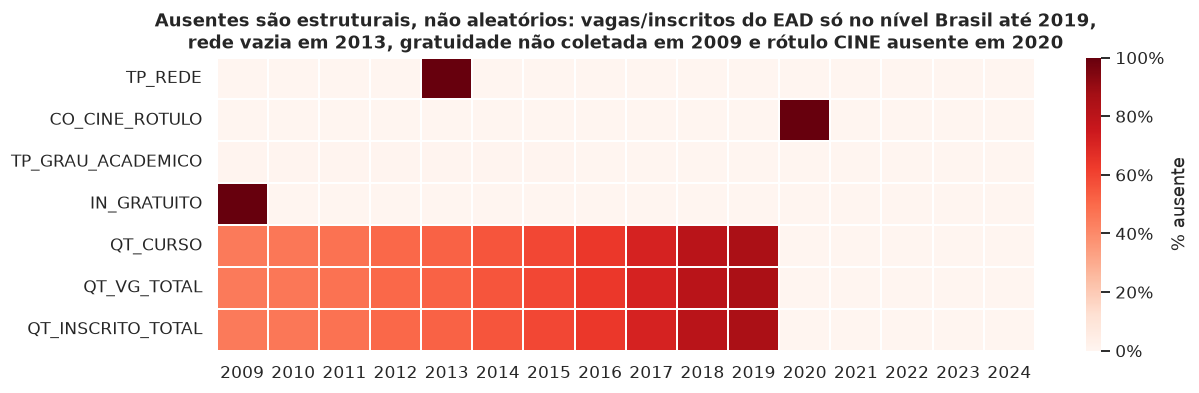

Colunas com algum ausente: 7 de 101 analisadas


In [8]:
cols = L.COLS_ID + L.COLS_QT
disp = set(tipos.column_name)
expr = ", ".join(f"avg(({L.nulo(c)} is null)::int) as \"{c}\"" for c in cols if c in disp)
aus = sql(f"select NU_ANO_CENSO as ano, {expr} from bronze_cursos where TP_DIMENSAO in ('1','2','4') group by 1 order by 1").set_index("ano").T
aus = aus[aus.max(axis=1) > 0.001]
fig, ax = plt.subplots(figsize=(12, 0.28 * len(aus) + 1.5))
sns.heatmap(aus, cmap="Reds", vmin=0, vmax=1, ax=ax, cbar_kws={"format": pct, "label": "% ausente"}, linewidths=0.3)
ax.set_title("Ausentes são estruturais, não aleatórios: vagas/inscritos do EAD só no nível Brasil até 2019,\n"
             "rede vazia em 2013, gratuidade não coletada em 2009 e rótulo CINE ausente em 2020")
ax.set_xlabel(""); ax.set_ylabel("")
salvar(fig, "eda_ausentes_por_ano"); plt.show()
print(f"Colunas com algum ausente: {len(aus)} de {len([c for c in cols if c in disp])} analisadas")

In [9]:
dup = sql('''
    select count(*) as linhas,
           count(*) - count(distinct (NU_ANO_CENSO, CO_CURSO, CO_MUNICIPIO, TP_DIMENSAO)) as chave_repetida
    from bronze_cursos''')
display(dup)

dominio = sql('''
    select 'Categoria administrativa 6/8/9 (só 2009)' as verificacao, count(*) as linhas from bronze_cursos where TP_CATEGORIA_ADMINISTRATIVA in ('6','8','9')
    union all select 'CO_CINE_ROTULO com aspas', count(*) from bronze_cursos where CO_CINE_ROTULO like '%"%'
    union all select 'Cursos sequenciais (fora do escopo)', count(*) from bronze_cursos where TP_NIVEL_ACADEMICO = '2'
    union all select 'TP_DIMENSAO = 3 (EAD só nível Brasil: risco de dupla contagem)', count(*) from bronze_cursos where TP_DIMENSAO = '3'
    union all select 'TP_REDE ausente', count(*) from bronze_cursos where nullif(trim(TP_REDE),'') is null
    union all select 'UF ausente em curso presencial/EAD por município', count(*) from bronze_cursos where nullif(trim(CO_UF),'') is null and TP_DIMENSAO in ('1','2')
    union all select 'ENADE: nota geral fora de 0–100', count(*) from bronze_enade where try_cast(replace(NT_GER, ',', '.') as double) not between 0 and 100
    union all select 'ENADE: presente (555) sem nota geral', count(*) from bronze_enade where TP_PRES = '555' and nullif(trim(NT_GER), '') is null
''')
display(dominio)

,linhas,chave_repetida
0,3851933,0


,verificacao,linhas
0,Categoria administrativa 6/8/9 (só 2009),40227
1,CO_CINE_ROTULO com aspas,3507242
2,Cursos sequenciais (fora do escopo),1732
3,TP_DIMENSAO = 3 (EAD só nível Brasil: risco de...,64420
4,TP_REDE ausente,64865
5,UF ausente em curso presencial/EAD por município,13
6,ENADE: nota geral fora de 0–100,0
7,ENADE: presente (555) sem nota geral,824


### 2.3 Análise univariada

In [10]:
uni = sql('''
    select try_cast(QT_MAT as integer) qt_mat, try_cast(QT_ING as integer) qt_ing, try_cast(QT_CONC as integer) qt_conc,
           try_cast(TP_MODALIDADE_ENSINO as tinyint) modalidade
    from bronze_cursos where TP_DIMENSAO in ('1','2') and coalesce(TP_NIVEL_ACADEMICO,'1') <> '2' ''')
display(uni[["qt_mat", "qt_ing", "qt_conc"]].describe(percentiles=[.25, .5, .75, .9, .99]).T
          .assign(assimetria=uni[["qt_mat", "qt_ing", "qt_conc"]].skew()))

,count,mean,std,min,25%,50%,75%,90%,99%,max,assimetria
qt_mat,"3,783,578.00",34.35,125.17,0.00,1.00,2.00,13.00,85.00,512.00,"16,351.00",16.35
qt_ing,"3,783,578.00",14.24,48.23,0.00,1.00,2.00,7.00,38.00,190.00,"12,082.00",22.84
qt_conc,"3,783,578.00",4.93,22.65,0.00,0.00,0.00,1.00,11.00,84.00,"6,441.00",47.75


In [11]:
card = sql('''select count(distinct CO_CURSO) cursos, count(distinct CO_IES) ies, count(distinct NO_CURSO) nomes_de_curso,
                     count(distinct CO_CINE_ROTULO) rotulos_cine, count(distinct CO_MUNICIPIO) municipios from bronze_cursos''')
display(card)
freq = sql('''select TP_MODALIDADE_ENSINO modalidade, TP_REDE rede, TP_GRAU_ACADEMICO grau, count(*) linhas
              from bronze_cursos where NU_ANO_CENSO = '2024' and TP_DIMENSAO in ('1','2') group by all order by linhas desc''')
display(freq.head(10))

,cursos,ies,nomes_de_curso,rotulos_cine,municipios
0,70335,3759,9626,386,3827


,modalidade,rede,grau,linhas
0,2,2,3,326751
1,2,2,1,213080
2,2,2,2,123846
3,1,2,1,17788
4,1,1,1,5964
5,2,1,2,4809
6,1,2,3,3876
7,1,1,2,3500
8,2,1,1,2544
9,1,2,2,2029


In [12]:
# outliers: IQR na escala original, IQR em log1p e z-score (|z| > 3) das matrículas por curso
x = uni.loc[uni.qt_mat > 0, "qt_mat"]
q1, q3 = x.quantile([.25, .75]); lim_iqr = q3 + 1.5 * (q3 - q1)
lx = np.log1p(x); lq1, lq3 = lx.quantile([.25, .75]); lim_log = np.expm1(lq3 + 1.5 * (lq3 - lq1))
z = (x - x.mean()) / x.std()
print(f"Limite IQR (escala original): {lim_iqr:,.0f} matrículas → {(x > lim_iqr).mean():.1%} das linhas seriam outliers")
print(f"Limite IQR (log1p):           {lim_log:,.0f} matrículas → {(x > lim_log).mean():.1%}")
print(f"z-score > 3:                  {(z > 3).mean():.1%}")
maiores = sql('''select NU_ANO_CENSO ano, NO_CURSO curso, CO_IES ies, case TP_MODALIDADE_ENSINO when '2' then 'EAD' else 'Presencial' end modalidade,
                        try_cast(QT_MAT as integer) matriculas
                 from bronze_cursos where TP_DIMENSAO in ('1','2') order by matriculas desc nulls last limit 8''')
display(maiores)

Limite IQR (escala original): 46 matrículas → 16.8% das linhas seriam outliers
Limite IQR (log1p):           631 matrículas → 0.8%
z-score > 3:                  1.6%


,ano,curso,ies,modalidade,matriculas
0,2011,SERVIÇO SOCIAL,829,EAD,16351
1,2012,SERVIÇO SOCIAL,829,EAD,16063
2,2024,Pedagogia,316,EAD,13985
3,2010,GESTÃO PÚBLICA,14724,EAD,12024
4,2011,GESTÃO PÚBLICA,14724,EAD,11745
5,2023,Pedagogia,316,EAD,11586
6,2011,PEDAGOGIA,1535,EAD,11359
7,2018,DIREITO,374,Presencial,9739


A distribuição de matrículas por curso é extremamente assimétrica (mediana na casa das dezenas, cauda de dezenas de milhares).
O IQR na escala original marca uma fração grande da base, o que não serve como critério. Em log1p, o limite isola os cursos
realmente grandes: **são fenômeno real** (cursos EAD de Pedagogia, Administração e Direito de grandes grupos), e não erro de digitação.
Decisão na limpeza: **manter e marcar** (`fl_outlier_mat`).

### 2.4 Análise bivariada e temporal

In [13]:
biv = sql('''select ano, ds_modalidade_ensino, ds_rede, sum(qt_mat) mat from silver_cursos where fl_conta_alunos and ano in (2009, 2024) group by all''')
ct = biv.pivot_table(index=["ano", "ds_rede"], columns="ds_modalidade_ensino", values="mat", aggfunc="sum")
tot_ano = ct.groupby(level="ano").sum().sum(axis=1)
display((ct.div(tot_ano.reindex(ct.index.get_level_values("ano")).values, axis=0) * 100).round(1).rename_axis(columns="% das matrículas do ano"))

% das matrículas do ano   EAD  Presencial
ano  ds_rede                             
2009 Privada            11.20       63.20
     Pública             2.90       22.70
2024 Privada            48.60       31.20
     Pública             2.10       18.10

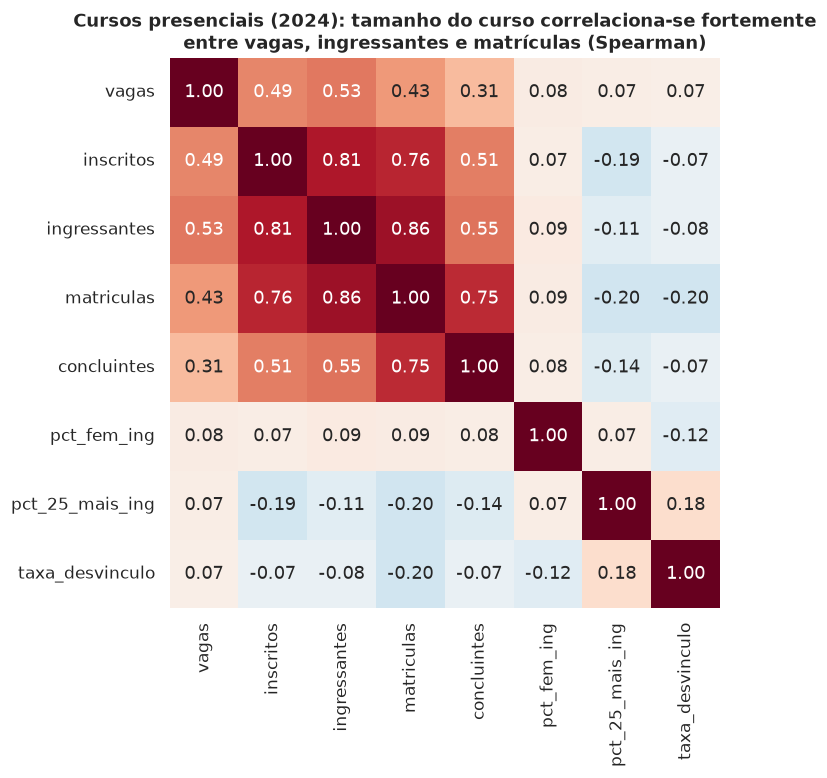

In [14]:
corr = sql('''select qt_vg_total vagas, qt_inscrito_total inscritos, qt_ing ingressantes, qt_mat matriculas, qt_conc concluintes,
                     qt_ing_fem::double / nullif(qt_ing, 0) pct_fem_ing, qt_ing_25_mais::double / nullif(qt_ing, 0) pct_25_mais_ing,
                     qt_sit_desvinculado::double / nullif(qt_mat + qt_sit_desvinculado, 0) taxa_desvinculo
              from silver_cursos where ano = 2024 and tp_dimensao = 1 and qt_mat > 0''').corr(method="spearman")
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, square=True, cbar=False)
ax.set_title("Cursos presenciais (2024): tamanho do curso correlaciona-se fortemente\nentre vagas, ingressantes e matrículas (Spearman)")
salvar(fig, "eda_correlacao"); plt.show()

### 2.5 Lista priorizada de problemas de qualidade (entrada da Etapa 3)

| # | Problema | Impacto se ignorado |
|---|---|---|
| 1 | Cursos EAD aparecem em **duas dimensões** (por município de oferta e “somente nível Brasil”) | Dupla contagem de vagas/inscritos EAD; totais errados |
| 2 | **Categorias administrativas 6/8/9 só em 2009** (“particular”, comunitária, confessional) | Quebra na série 2009→2010 por categoria |
| 3 | **Escola de origem** zerada em 2009 e parcial em 2010–2012 | “Salto” artificial de 0% para 71% de egressos de escola pública |
| 4 | **Cor/raça não declarada** em ~70% dos ingressantes até 2013 | % PPI subestimado nos primeiros anos |
| 5 | **Rede (pública/privada) vazia em 2013** | Série pública × privada interrompida em 2013 |
| 6 | Tudo como texto; marcador `.`; códigos CINE com aspas | Tipos errados, junções e filtros falham |
| 7 | Cursos **sequenciais** misturados à graduação | Fora do escopo das estatísticas oficiais |
| 8 | ENADE: ausentes/eliminados sem nota; arquivos LGPD não ligáveis entre si | Médias enviesadas se ausentes entrarem como zero |
| 9 | Municípios do INEP sem correspondência no IBGE; população de 2023 sem estimativa publicada | Perda de linhas nas taxas por habitante |
| 10 | Cursos com matrículas extremas | Distorcem médias por curso |

## 3. Limpeza e tratamento: log de decisões

Cada problema recebeu uma decisão justificada e o número de linhas afetadas (`src/limpeza.py` → `reports/log_limpeza.csv`).

In [15]:
log = pd.read_csv(C.REPORTS / "log_limpeza.csv")
with pd.option_context("display.max_colwidth", 120):
    display(log[["etapa", "problema", "decisao", "linhas_afetadas", "linhas_antes", "linhas_depois"]])

,etapa,problema,decisao,linhas_afetadas,linhas_antes,linhas_depois
0,censo,Nomes de colunas em MAIÚSCULAS com prefixos INEP,Padronizados para snake_case sem acento; 227→101 colunas mantidas (demais seguem no bronze),3851933,"3,851,933.00","3,851,933.00"
1,censo,Tipos: tudo VARCHAR no bronze,Cast para TINYINT/SMALLINT/INTEGER com try_cast,0,NaN,NaN
2,censo,"CO_CINE_ROTULO com aspas duplicadas (ex.: """"""0011A09"""""")",Removidas as aspas,3507242,NaN,NaN
3,censo,Marcador '.' (não aplicável) em campos numéricos,Convertido para NULL,0,NaN,NaN
4,censo,Cursos sequenciais de formação específica (TP_NIVEL_ACADEMICO=2),Removidos,1732,"3,851,933.00","3,850,201.00"
5,censo,Linhas duplicadas exatas,Removidas,0,"3,850,201.00","3,850,201.00"
6,censo,"Chave (ano, curso, município, dimensão) repetida com conteúdo diferente",Mantidas e marcadas (fl_chave_duplicada),0,NaN,NaN
7,censo,TP_DIMENSAO=3: EAD 'somente nível Brasil' repete o curso EAD sem alunos por município,Mantidas e marcadas (fl_conta_alunos=false); excluídas de somas de ingressantes/matrículas,64381,NaN,NaN
8,censo,TP_DIMENSAO=4: EAD ofertado no exterior (sem UF),Mantidas; UF = 'Exterior' em análises regionais,2242,NaN,NaN
9,censo,Categorias administrativas 6/8/9 (particular/comunitária/confessional) existem só em 2009,"Herdada a categoria declarada pela mesma IES em 2010 (39,652 linhas); sem IES em 2010: 6→4 (com fins lucrativos), 8/...",39953,NaN,NaN


In [16]:
n_bronze = sql("select count(*) n from bronze_cursos").n[0]
n_silver = sql("select count(*) n from silver_cursos").n[0]
print(f"Censo cursos: {n_bronze:,} linhas no bronze → {n_silver:,} na silver ({n_bronze - n_silver:,} removidas: cursos sequenciais)")
print(f"Colunas: {len(tipos) - 1} no bronze (união dos layouts 2009–2024) → {len(sql('describe silver_cursos'))} na silver (inclui flags e variáveis derivadas)")

Censo cursos: 3,851,933 linhas no bronze → 3,850,201 na silver (1,732 removidas: cursos sequenciais)
Colunas: 227 no bronze (união dos layouts 2009–2024) → 117 na silver (inclui flags e variáveis derivadas)


## 4. Visualizações e respostas às perguntas

### P1: Crescimento e EAD

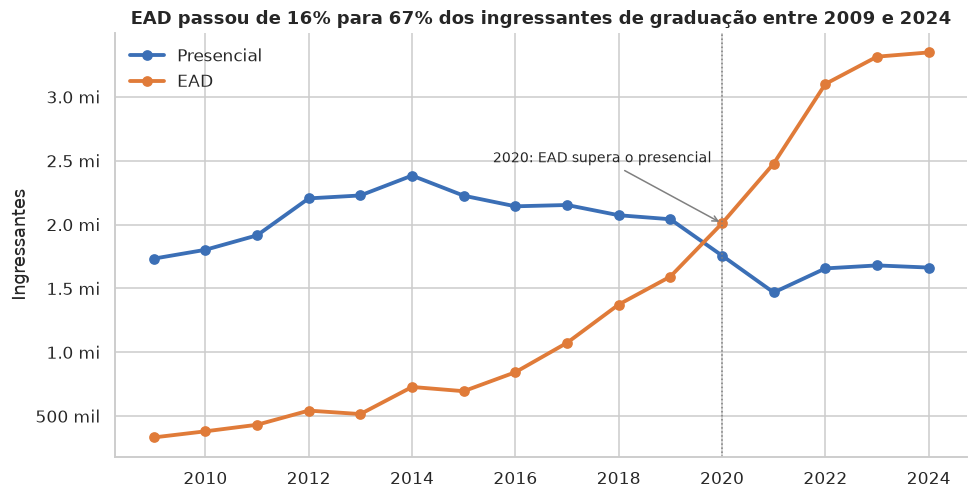

Matrículas: 5,954,021 (2009) → 10,226,873 (2024), +4,272,852; o EAD respondeu por 102% do crescimento; o presencial variou -78,414


In [17]:
s = gold["serie_brasil"].groupby(["ano", "ds_modalidade_ensino"], as_index=False)[["qt_ing", "qt_mat"]].sum()
ing = s.pivot(index="ano", columns="ds_modalidade_ensino", values="qt_ing")
p0, p1 = ing.loc[2009].EAD / ing.loc[2009].sum(), ing.loc[2024].EAD / ing.loc[2024].sum()
cruz = ing.index[(ing.EAD > ing.Presencial)].min()

fig, ax = plt.subplots(figsize=(10, 5))
for m in ["Presencial", "EAD"]:
    ax.plot(ing.index, ing[m], marker="o", lw=2.5, color=COR[m], label=m)
ax.axvline(cruz, color="grey", ls=":", lw=1)
ax.annotate(f"{cruz}: EAD supera o presencial", (cruz, ing.loc[cruz].EAD), xytext=(-150, 40), textcoords="offset points",
            arrowprops=dict(arrowstyle="->", color="grey"), fontsize=9)
ax.yaxis.set_major_formatter(mil)
ax.set_title(f"EAD passou de {p0:.0%} para {p1:.0%} dos ingressantes de graduação entre 2009 e 2024")
ax.set_xlabel(""); ax.set_ylabel("Ingressantes"); ax.legend(frameon=False)
salvar(fig, "v1_ingressantes_modalidade"); plt.show()

mat = s.pivot(index="ano", columns="ds_modalidade_ensino", values="qt_mat")
d_tot = mat.loc[2024].sum() - mat.loc[2009].sum(); d_ead = mat.loc[2024].EAD - mat.loc[2009].EAD
print(f"Matrículas: {mat.loc[2009].sum():,.0f} (2009) → {mat.loc[2024].sum():,.0f} (2024), +{d_tot:,.0f}; "
      f"o EAD respondeu por {d_ead/d_tot:.0%} do crescimento; o presencial variou {mat.loc[2024].Presencial - mat.loc[2009].Presencial:+,.0f}")

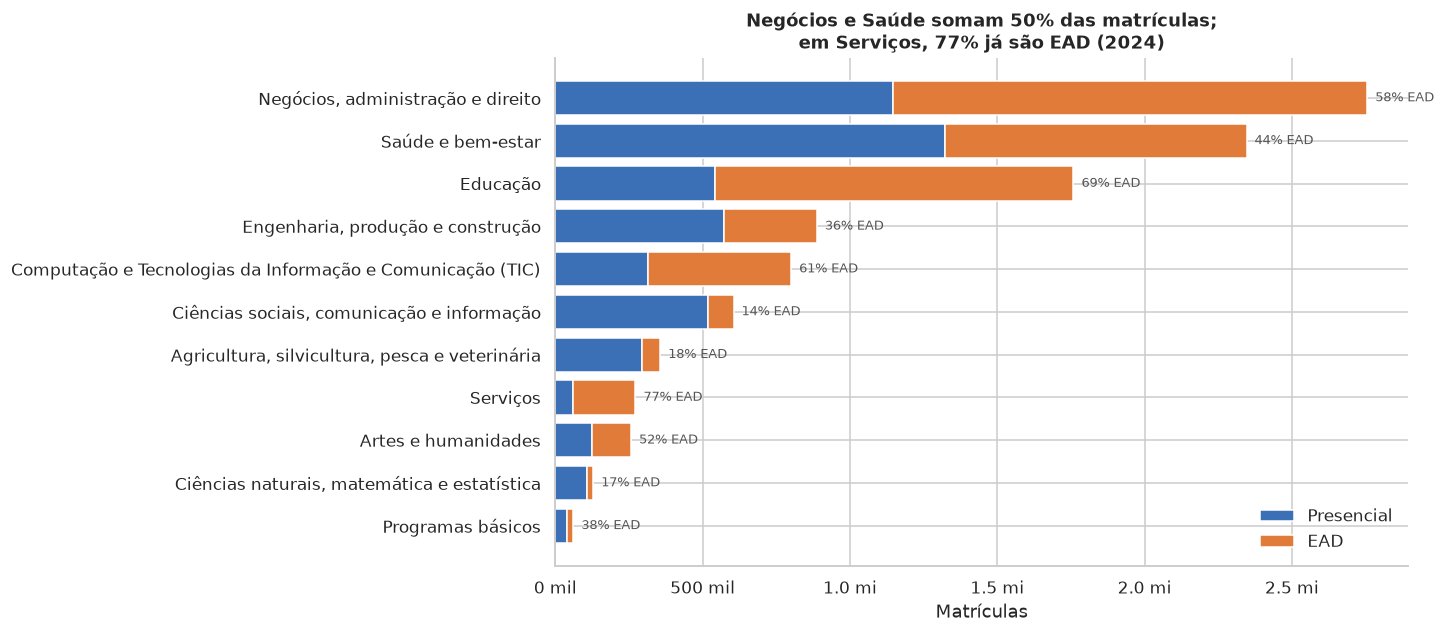

In [18]:
a = gold["area_ano"].query("ano == 2024").pivot_table(index="no_cine_area_geral", columns="ds_modalidade_ensino", values="qt_mat", aggfunc="sum").fillna(0)
a["total"] = a.sum(axis=1); a["pct_ead"] = a.EAD / a.total
a = a.sort_values("total")
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(a.index, a.Presencial, color=COR["Presencial"], label="Presencial")
ax.barh(a.index, a.EAD, left=a.Presencial, color=COR["EAD"], label="EAD")
for i, (t, p) in enumerate(zip(a.total, a.pct_ead)):
    ax.text(t, i, f"  {p:.0%} EAD", va="center", fontsize=8.5, color="#555")
ax.xaxis.set_major_formatter(mil)
top_ead = a.sort_values("pct_ead").index[-1]
t2 = a.sort_values("total", ascending=False).head(2)
ax.set_title(f"{t2.index[0].split(',')[0]} e {t2.index[1].split(' e ')[0]} somam {t2.total.sum()/a.total.sum():.0%} das matrículas;\n"
             f"em {top_ead}, {a.loc[top_ead].pct_ead:.0%} já são EAD (2024)")
ax.set_xlabel("Matrículas"); ax.set_ylabel(""); ax.legend(frameon=False, loc="lower right")
salvar(fig, "v2_matriculas_area"); plt.show()

### P2: Desigualdade regional (taxas por 100 mil habitantes, população IBGE)

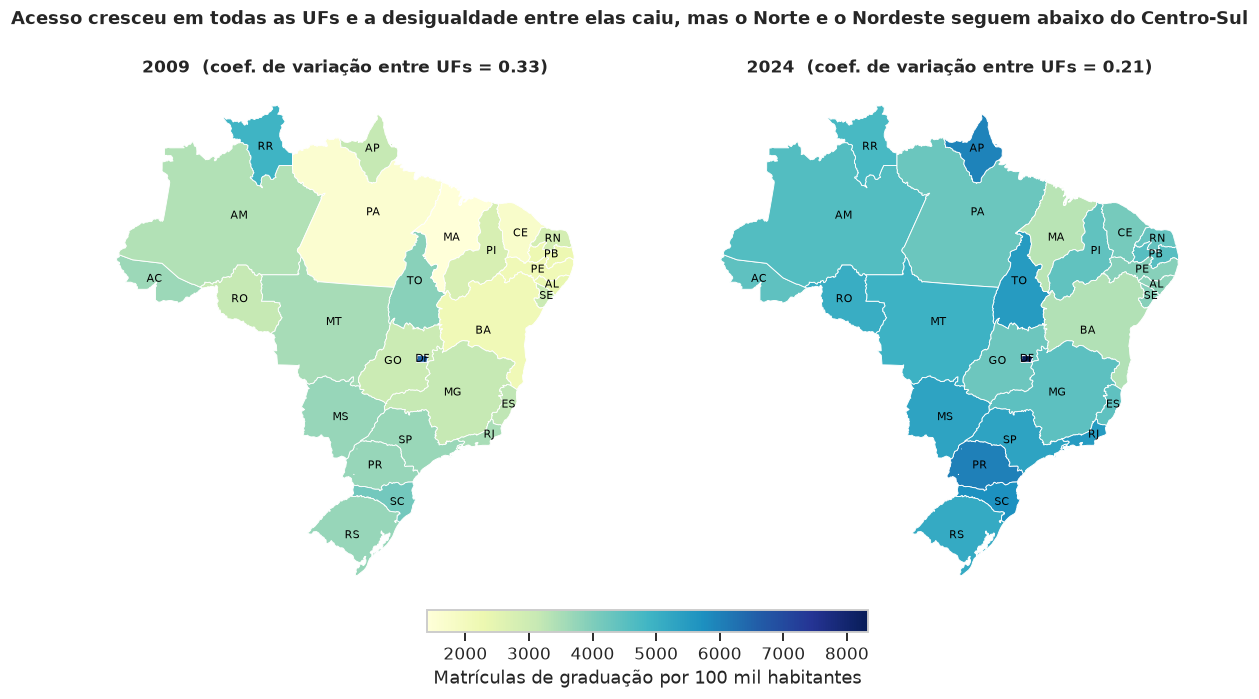

In [19]:
uf = gold["uf_ano"].copy()
malha = gpd.read_file(C.RAW_IBGE / "malha_uf.geojson")
malha["co_uf"] = malha.codarea.astype(int)
g = malha.merge(uf[uf.ano.isin([2009, 2024])], on="co_uf")
vmin, vmax = g.tx_mat_100mil.min(), g.tx_mat_100mil.max()
cv = uf.groupby("ano").tx_mat_100mil.agg(lambda s: s.std() / s.mean())

fig, axs = plt.subplots(1, 2, figsize=(13, 6.5))
for ax, ano in zip(axs, [2009, 2024]):
    gg = g[g.ano == ano]
    gg.plot(column="tx_mat_100mil", cmap="YlGnBu", vmin=vmin, vmax=vmax, ax=ax, edgecolor="white", linewidth=0.6)
    for _, r in gg.iterrows():
        p = r.geometry.representative_point()
        ax.text(p.x, p.y, r.sg_uf, ha="center", va="center", fontsize=7, color="black")
    ax.set_title(f"{ano}  (coef. de variação entre UFs = {cv[ano]:.2f})", fontsize=11); ax.axis("off")
sm = plt.cm.ScalarMappable(cmap="YlGnBu", norm=plt.Normalize(vmin, vmax))
fig.colorbar(sm, ax=axs, orientation="horizontal", fraction=0.04, pad=0.02, label="Matrículas de graduação por 100 mil habitantes")
fig.suptitle("Acesso cresceu em todas as UFs e a desigualdade entre elas caiu, mas o Norte e o Nordeste seguem abaixo do Centro-Sul",
             fontweight="bold", fontsize=12)
salvar(fig, "v3_mapa_taxa_uf"); plt.show()

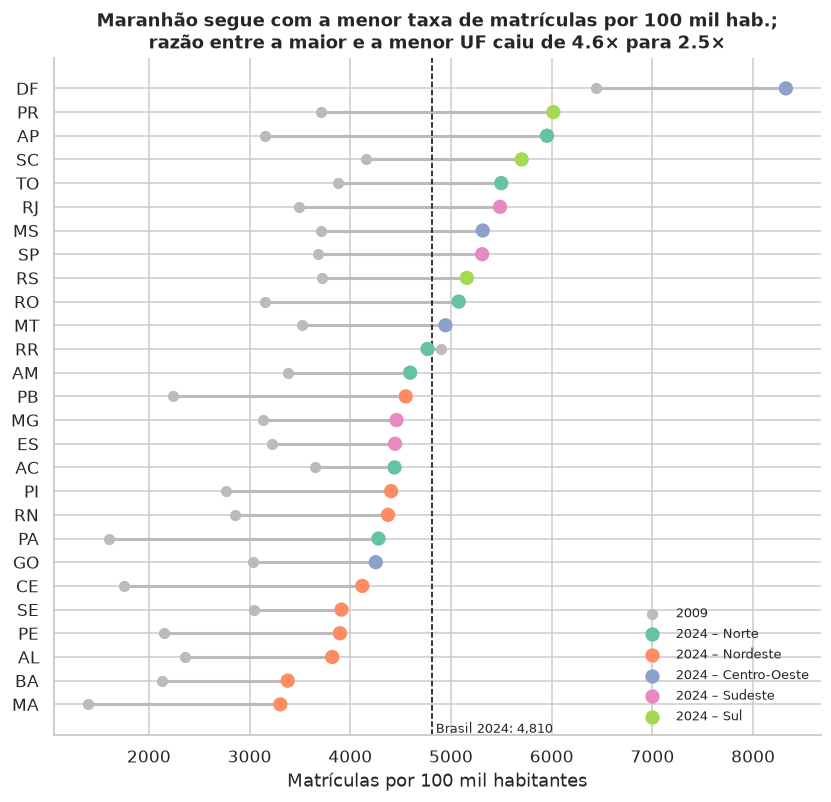

In [20]:
d = uf[uf.ano.isin([2009, 2024])].pivot(index="sg_uf", columns="ano", values="tx_mat_100mil").sort_values(2024)
reg = uf.drop_duplicates("sg_uf").set_index("sg_uf").no_regiao
cores_reg = dict(zip(["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"], sns.color_palette("Set2", 5)))
fig, ax = plt.subplots(figsize=(9, 8))
ax.hlines(d.index, d[2009], d[2024], color="#bbb", lw=2)
ax.scatter(d[2009], d.index, color="#bbb", s=40, label="2009", zorder=3)
ax.scatter(d[2024], d.index, c=[cores_reg[reg[u]] for u in d.index], s=70, zorder=3)
for r_, c_ in cores_reg.items():
    ax.scatter([], [], color=c_, s=70, label=f"2024 – {r_}")
br = uf.groupby("ano").apply(lambda x: 1e5 * x.qt_mat.sum() / x.populacao.sum())
ax.axvline(br[2024], color="black", ls="--", lw=1); ax.text(br[2024], -1.2, f" Brasil 2024: {br[2024]:,.0f}", fontsize=8.5)
ax.set_title(f"Maranhão segue com a menor taxa de matrículas por 100 mil hab.;\n"
             f"razão entre a maior e a menor UF caiu de {d[2009].max()/d[2009].min():.1f}× para {d[2024].max()/d[2024].min():.1f}×")
ax.set_xlabel("Matrículas por 100 mil habitantes"); ax.legend(frameon=False, fontsize=8.5, loc="lower right")
salvar(fig, "v4_taxa_uf_2009_2024"); plt.show()

### P3: Rede privada, FIES e PROUNI

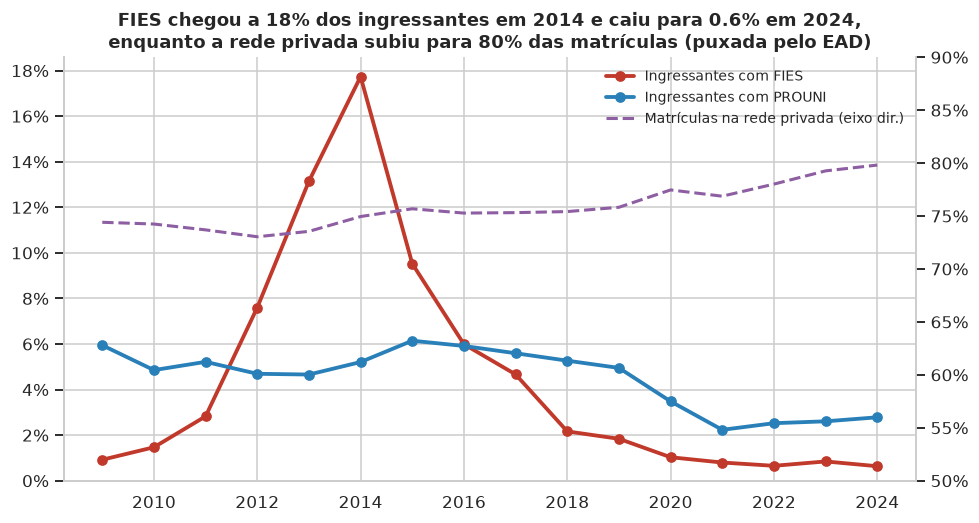

In [21]:
p = gold["perfil_ingressantes"].groupby("ano")[["qt_ing", "qt_ing_fies", "qt_ing_prouni"]].sum()
priv = gold["serie_brasil"].pivot_table(index="ano", columns="ds_rede", values="qt_mat", aggfunc="sum")
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(p.index, p.qt_ing_fies / p.qt_ing, marker="o", lw=2.5, color="#c0392b", label="Ingressantes com FIES")
ax.plot(p.index, p.qt_ing_prouni / p.qt_ing, marker="o", lw=2.5, color="#2980b9", label="Ingressantes com PROUNI")
ax2 = ax.twinx()
ax2.plot(priv.index, priv.Privada / priv.sum(axis=1), color=COR["Privada"], ls="--", lw=2, label="Matrículas na rede privada (eixo dir.)")
ax2.set_ylim(0.5, 0.9); ax2.yaxis.set_major_formatter(pct); ax2.grid(False); ax2.spines["right"].set_visible(True)
ax.yaxis.set_major_locator(mtick.MultipleLocator(0.02)); ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, None)
pico = (p.qt_ing_fies / p.qt_ing).idxmax()
ax.set_title(f"FIES chegou a {p.loc[pico].qt_ing_fies/p.loc[pico].qt_ing:.0%} dos ingressantes em {pico} e caiu para "
             f"{p.loc[2024].qt_ing_fies/p.loc[2024].qt_ing:.1%} em 2024,\nenquanto a rede privada subiu para "
             f"{priv.loc[2024].Privada/priv.loc[2024].sum():.0%} das matrículas (puxada pelo EAD)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, frameon=False, loc="upper right", fontsize=9)
salvar(fig, "v5_fies_prouni_privada"); plt.show()

### P4: Perfil do ingressante

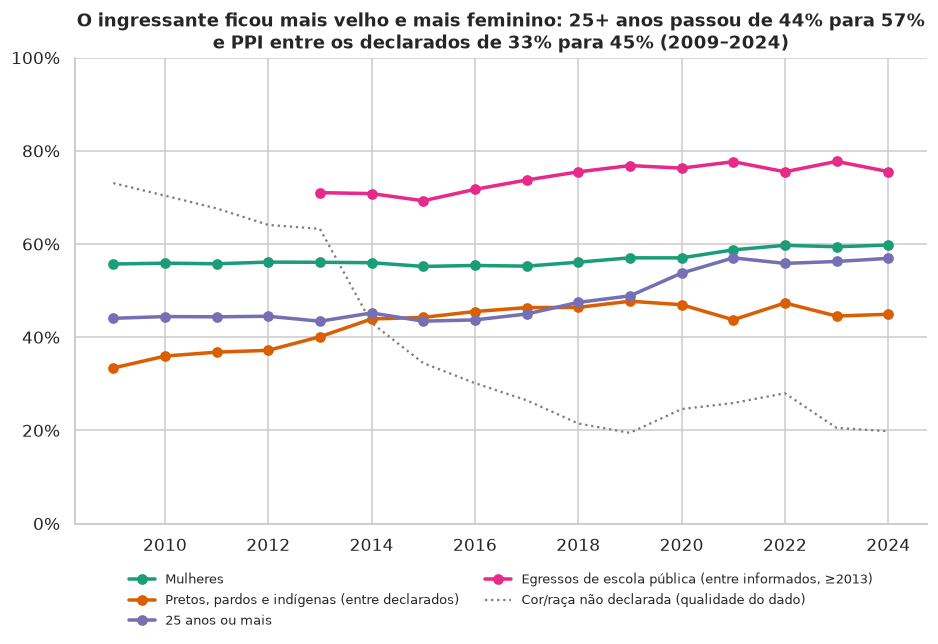

,Mulheres,"Pretos, pardos e indígenas (entre declarados)",25 anos ou mais,"Egressos de escola pública (entre informados, ≥2013)"
ano,,,,
2009,55.7%,33.4%,44.0%,–
2013,56.1%,40.1%,43.4%,71.0%
2019,57.0%,47.7%,48.9%,76.8%
2024,59.8%,44.9%,56.9%,75.5%


In [22]:
pf = gold["perfil_ingressantes"].groupby("ano").sum(numeric_only=True)
ind = pd.DataFrame({
    "Mulheres": pf.qt_ing_fem / pf.qt_ing,
    "Pretos, pardos e indígenas (entre declarados)": pf.qt_ing_ppi / (pf.qt_ing - pf.qt_ing_cor_nd),
    "25 anos ou mais": pf.qt_ing_25_mais / pf.qt_ing,
    "Egressos de escola pública (entre informados, ≥2013)": (pf.qt_ing_escola_publica / (pf.qt_ing_escola_publica + pf.qt_ing_escola_privada)).where(pf.index >= 2013),
})
nd = pf.qt_ing_cor_nd / pf.qt_ing
fig, ax = plt.subplots(figsize=(10, 5.5))
for (nome, serie), c in zip(ind.items(), sns.color_palette("Dark2", 4)):
    ax.plot(serie.index, serie, marker="o", lw=2.3, label=nome, color=c)
ax.plot(nd.index, nd, color="grey", ls=":", lw=1.5, label="Cor/raça não declarada (qualidade do dado)")
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1)
ax.set_title(f"O ingressante ficou mais velho e mais feminino: 25+ anos passou de {ind.iloc[0, 2]:.0%} para {ind.iloc[-1, 2]:.0%}\n"
             f"e PPI entre os declarados de {ind.iloc[0, 1]:.0%} para {ind.iloc[-1, 1]:.0%} (2009–2024)")
ax.legend(frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2)
salvar(fig, "v6_perfil_ingressantes"); plt.show()
display(ind.loc[[2009, 2013, 2019, 2024]].map(lambda v: f"{v:.1%}" if pd.notna(v) else "–"))

In [23]:
# perfil por modalidade em 2024: o EAD concentra o ingressante mais velho
m = gold["perfil_ingressantes"].query("ano == 2024").groupby("ds_modalidade_ensino").sum(numeric_only=True)
display(pd.DataFrame({"% 25 anos ou mais": m.qt_ing_25_mais / m.qt_ing, "% mulheres": m.qt_ing_fem / m.qt_ing,
                      "% noturno (presencial)": (m.qt_ing_noturno / m.qt_ing).where(m.index == "Presencial")}).map(lambda v: f"{v:.1%}" if pd.notna(v) else "–"))

,% 25 anos ou mais,% mulheres,% noturno (presencial)
ds_modalidade_ensino,,,
EAD,70.0%,60.6%,–
Presencial,30.6%,58.1%,59.9%


### P5: Desempenho no ENADE

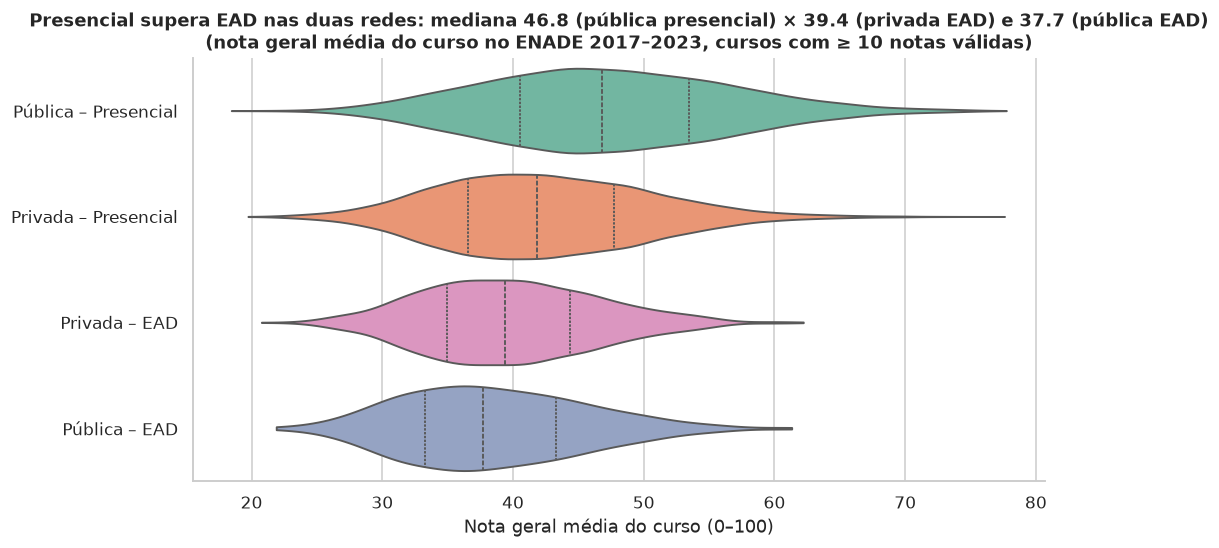

,cursos,mediana,p25,p75
grupo,,,,
Pública – Presencial,11376,46.79,40.54,53.48
Privada – Presencial,23438,41.86,36.56,47.71
Privada – EAD,1693,39.42,34.97,44.38
Pública – EAD,408,37.74,33.24,43.29


In [24]:
ec = gold["enade_curso"].query("n_notas_validas >= 10 and ds_rede.notna()").copy()
ec["grupo"] = ec.ds_rede + " – " + ec.ds_modalidade_enade
ordem = ec.groupby("grupo").nt_ger_media.median().sort_values(ascending=False).index
fig, ax = plt.subplots(figsize=(10, 5))
sns.violinplot(data=ec, y="grupo", x="nt_ger_media", order=ordem, hue="grupo", palette="Set2", inner="quartile", cut=0, ax=ax, legend=False)
med = ec.groupby("grupo").nt_ger_media.median()
ax.set_title(f"Presencial supera EAD nas duas redes: mediana {med['Pública – Presencial']:.1f} (pública presencial) × "
             f"{med['Privada – EAD']:.1f} (privada EAD) e {med['Pública – EAD']:.1f} (pública EAD)\n"
             f"(nota geral média do curso no ENADE 2017–2023, cursos com ≥ 10 notas válidas)")
ax.set_xlabel("Nota geral média do curso (0–100)"); ax.set_ylabel("")
salvar(fig, "v7_enade_distribuicao"); plt.show()
display(ec.groupby("grupo").agg(cursos=("co_curso", "size"), mediana=("nt_ger_media", "median"),
                                 p25=("nt_ger_media", lambda s: s.quantile(.25)), p75=("nt_ger_media", lambda s: s.quantile(.75))).loc[ordem])

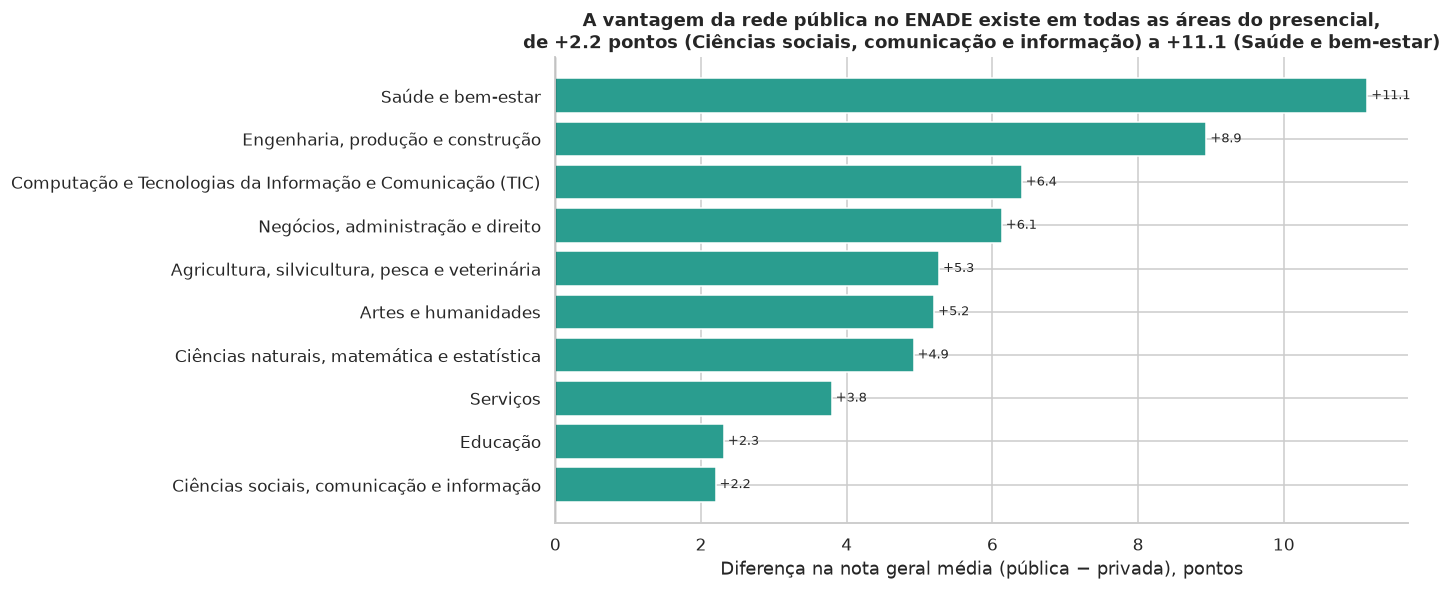

In [25]:
r = gold["enade_resumo"].query("ds_rede in ['Pública', 'Privada'] and ds_modalidade_enade == 'Presencial'")
r = r.assign(soma=r.nt_ger_media * r.n_notas_validas).groupby(["no_cine_area_geral", "ds_rede"])[["soma", "n_notas_validas"]].sum()
r = (r.soma / r.n_notas_validas).unstack().dropna()
r["gap"] = r["Pública"] - r["Privada"]; r = r.sort_values("gap")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(r.index, r.gap, color=[COR["Pública"] if g > 0 else COR["Privada"] for g in r.gap])
for i, v in enumerate(r.gap):
    ax.text(v, i, f" {v:+.1f}", va="center", fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_title(f"A vantagem da rede pública no ENADE existe em todas as áreas do presencial,\n"
             f"de {r.gap.min():+.1f} pontos ({r.index[0]}) a {r.gap.max():+.1f} ({r.index[-1]})")
ax.set_xlabel("Diferença na nota geral média (pública − privada), pontos"); ax.set_ylabel("")
salvar(fig, "v8_enade_gap_area"); plt.show()

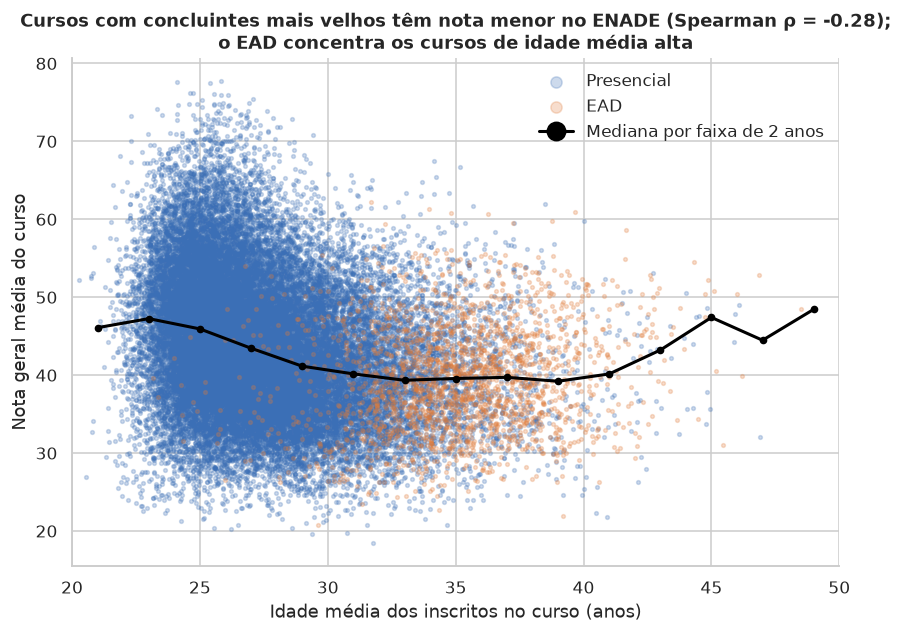

In [26]:
sc = ec.dropna(subset=["idade_media"])
rho = sc[["idade_media", "nt_ger_media"]].corr(method="spearman").iloc[0, 1]
fig, ax = plt.subplots(figsize=(9, 6))
for m in ["Presencial", "EAD"]:
    d_ = sc[sc.ds_modalidade_enade == m]
    ax.scatter(d_.idade_media, d_.nt_ger_media, s=6, alpha=0.25, color=COR[m], label=m)
faixa = sc.groupby(pd.cut(sc.idade_media, np.arange(20, 51, 2)), observed=True).nt_ger_media.median()
ax.plot([i.mid for i in faixa.index], faixa.values, color="black", lw=2, marker="o", ms=4, label="Mediana por faixa de 2 anos")
ax.set_xlim(20, 50)
ax.set_title(f"Cursos com concluintes mais velhos têm nota menor no ENADE (Spearman ρ = {rho:.2f});\n"
             f"o EAD concentra os cursos de idade média alta")
ax.set_xlabel("Idade média dos inscritos no curso (anos)"); ax.set_ylabel("Nota geral média do curso")
ax.legend(frameon=False, markerscale=3)
salvar(fig, "v9_enade_idade_nota"); plt.show()

### Antes × depois da limpeza

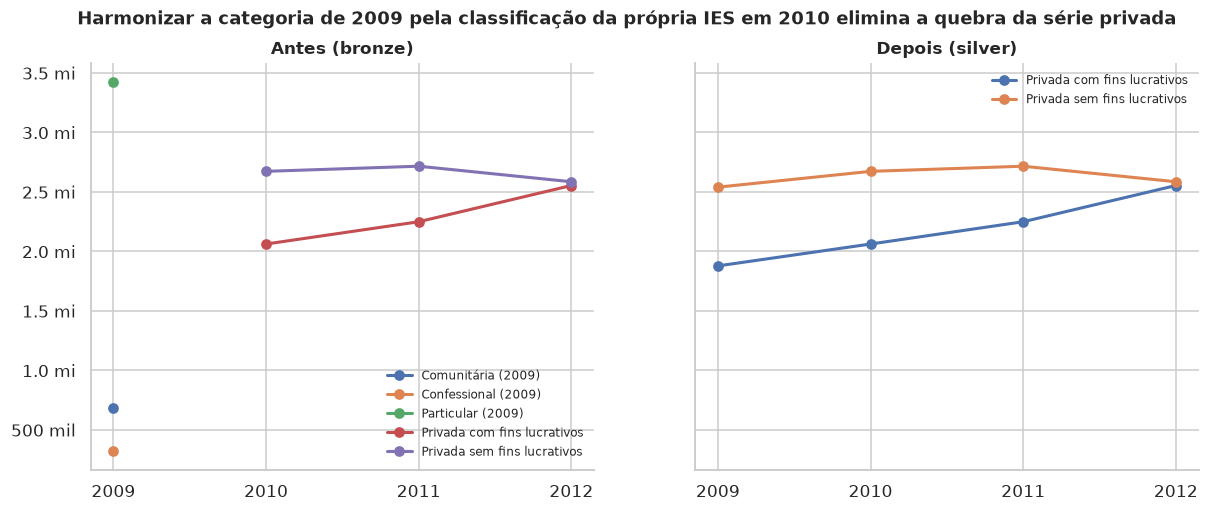

In [27]:
ad = gold["antes_depois_categoria"]
ad = ad[ad.ds_categoria_administrativa.str.contains("Privada|Particular|Comunitária|Confessional")]
fig, axs = plt.subplots(1, 2, figsize=(13, 4.8), sharey=True)
for ax, v in zip(axs, ["antes (bronze)", "depois (silver)"]):
    d_ = ad[ad.versao == v].pivot(index="ano", columns="ds_categoria_administrativa", values="qt_mat")
    for c in d_.columns:
        ax.plot(d_.index, d_[c], marker="o", lw=2, label=c)
    ax.set_title(v.capitalize(), fontsize=11); ax.yaxis.set_major_formatter(mil); ax.set_xticks(d_.index)
    ax.legend(frameon=False, fontsize=8)
fig.suptitle("Harmonizar a categoria de 2009 pela classificação da própria IES em 2010 elimina a quebra da série privada",
             fontweight="bold", fontsize=12)
salvar(fig, "v10_antes_depois_categoria"); plt.show()

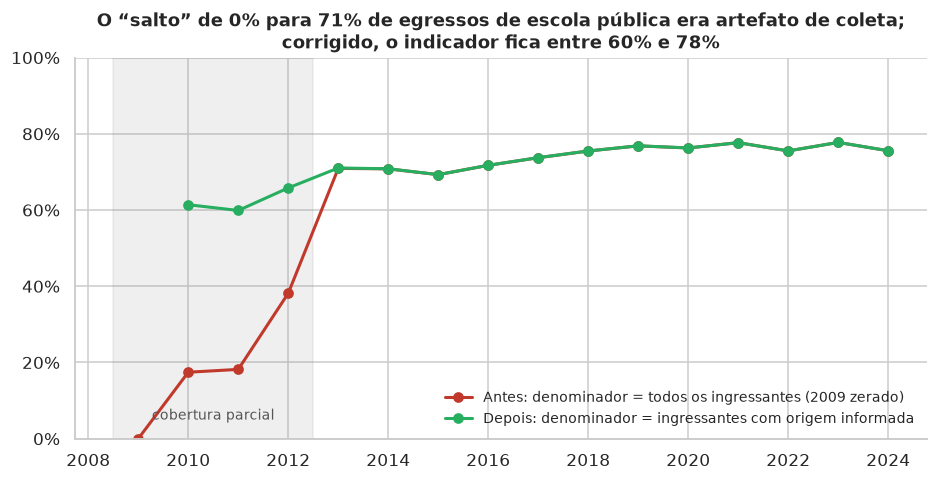

In [28]:
pf = gold["perfil_ingressantes"].groupby("ano").sum(numeric_only=True)
antes = pf.qt_ing_escola_publica / pf.qt_ing
depois = (pf.qt_ing_escola_publica / (pf.qt_ing_escola_publica + pf.qt_ing_escola_privada))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(antes.index, antes.fillna(0), marker="o", color="#c0392b", lw=2, label="Antes: denominador = todos os ingressantes (2009 zerado)")
ax.plot(depois.index, depois, marker="o", color="#27ae60", lw=2, label="Depois: denominador = ingressantes com origem informada")
ax.axvspan(2008.5, 2012.5, color="grey", alpha=0.12); ax.text(2010.5, 0.05, "cobertura parcial", ha="center", fontsize=9, color="#555")
ax.yaxis.set_major_formatter(pct); ax.set_ylim(0, 1)
ax.set_title("O “salto” de 0% para 71% de egressos de escola pública era artefato de coleta;\ncorrigido, o indicador fica entre 60% e 78%")
ax.legend(frameon=False, fontsize=9, loc="lower right")
salvar(fig, "v11_antes_depois_escola_publica"); plt.show()

## 5. Números-chave para o relatório

In [29]:
s = gold["serie_brasil"].groupby("ano").sum(numeric_only=True)
ead = gold["serie_brasil"].query("ds_modalidade_ensino == 'EAD'").groupby("ano").sum(numeric_only=True)
priv = gold["serie_brasil"].query("ds_rede == 'Privada'").groupby("ano").sum(numeric_only=True)
chave = pd.DataFrame({
    "ingressantes": s.qt_ing, "matrículas": s.qt_mat, "concluintes": s.qt_conc, "vagas oferecidas": s.qt_vagas,
    "% ingressantes EAD": ead.qt_ing / s.qt_ing, "% matrículas EAD": ead.qt_mat / s.qt_mat, "% matrículas privada": priv.qt_mat / s.qt_mat,
    "ingressantes por vaga": s.qt_ing / s.qt_vagas,
    "matrículas por 100 mil hab.": gold["uf_ano"].groupby("ano").apply(lambda x: 1e5 * x.qt_mat.sum() / x.populacao.sum()),
})
display(chave.style.format({c: "{:.1%}" for c in chave.columns if c.startswith("%")} | {"ingressantes por vaga": "{:.2f}"} |
                           {c: "{:,.0f}" for c in ["ingressantes", "matrículas", "concluintes", "vagas oferecidas", "matrículas por 100 mil hab."]}))

,ingressantes,matrículas,concluintes,vagas oferecidas,% ingressantes EAD,% matrículas EAD,% matrículas privada,ingressantes por vaga,matrículas por 100 mil hab.
ano,,,,,,,,,
2009,"2,065,082","5,954,021","959,197","4,726,394",16.1%,14.1%,74.4%,0.44,"3,109"
2010,"2,182,229","6,379,299","973,839","4,754,310",17.4%,14.6%,74.2%,0.46,"3,344"
2011,"2,346,695","6,739,689","1,016,713","4,453,431",18.4%,14.7%,73.7%,0.53,"3,503"
2012,"2,747,089","7,037,688","1,050,413","4,653,814",19.8%,15.8%,73.0%,0.59,"3,629"
2013,"2,742,950","7,305,977","991,010","5,850,435",18.8%,15.8%,73.5%,0.47,"3,634"
2014,"3,110,848","7,828,013","1,027,092","8,081,369",23.4%,17.1%,74.9%,0.38,"3,861"
2015,"2,920,222","8,027,297","1,150,067","8,530,655",23.8%,17.4%,75.7%,0.34,"3,926"
2016,"2,985,644","8,048,701","1,169,449","10,662,501",28.2%,18.6%,75.3%,0.28,"3,906"
2017,"3,226,249","8,286,663","1,199,769","10,779,086",33.3%,21.2%,75.3%,0.30,"3,990"


### Limitações
- O Censo é **declaratório** (as IES informam); cor/raça teve alta não declaração até 2013, e a escola de origem só tem cobertura plena a partir de 2013.
- No EAD, o município é o **polo de oferta**, não a residência do aluno: taxas por UF no EAD refletem onde estão os polos.
- ENADE: avalia **concluintes** de áreas que fazem prova no ano (ciclo trienal), então os anos não são comparáveis entre si por área;
  por LGPD, sexo e idade só existem agregados por curso, o que impede análise individual (falácia ecológica na V9).
- População de 2023 interpolada (sem estimativa IBGE publicada); 2022 vem do Censo Demográfico, o que gera pequena descontinuidade em relação às estimativas.

### Próximos passos (Parte 2)
- Modelar a nota do ENADE do curso com atributos do Censo (rede, modalidade, tamanho, perfil, área), controlando a composição dos alunos.
- Série temporal/previsão de ingressantes EAD × presencial por área; análise de evasão (desvinculados) por coorte.
- Desagregar por município (taxas por município com população municipal do IBGE) para mapas de acesso em nível local.